# 03_Demand_Forecasting: Baseline, LightGBM, Optuna, kiểm chứng phản ứng giá

**Phục vụ:** Chương 4 và mục 6.1 của báo cáo. **Đầu vào:** `features.parquet`, `feature_meta.json` (notebook 02), `elasticity_by_category.csv` (notebook 01).

| Bước | Nội dung | Mục báo cáo |
|---|---|---|
| 1 | Nạp dữ liệu, tách train / valid / test | 3.5 |
| 2 | Baseline: Moving Average 7 ngày, Seasonal Naive (lag 7) | 4.1 |
| 3 | LightGBM tham số mặc định | 4.2 |
| 4 | **Optuna** trên mẫu chuỗi, **ràng buộc đơn điệu** theo discount | 4.3 |
| 5 | Mô hình cuối, đánh giá trên test (tổng thể, theo nhóm ngành, nhóm bán chạy) | 4.4, 6.1 |
| 6 | Feature importance | 4.5 |
| 7 | **Kiểm chứng phản ứng giá**: độ co giãn ngầm định so với hồi quy fixed effects | 4.6 |
| 8 | Lưu mô hình cho notebook 04 | |

Chỉ số chính là **WAPE**, vì doanh số rất tập trung (20% sản phẩm chiếm 87% doanh số) nên WAPE phản ánh sai số theo đúng tầm quan trọng kinh doanh.

In [1]:
!pip install -q -U lightgbm optuna

In [2]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna

# ---- Cấu hình ----
USE_DRIVE = True
PROJECT = "Dynamic_Pricing_Project"
RANDOM_STATE = 42
N_TRIALS = 25             # số lần thử Optuna
TUNE_SERIES_FRAC = 0.10   # tỷ lệ chuỗi dùng để tune (giữ thời gian chạy ~15–20 phút)
MAX_ROUNDS = 3000
EARLY_STOP = 100
ELAST_SAMPLE = 50_000     # số dòng test dùng để đo độ co giãn ngầm định

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive") / PROJECT
    except ImportError:
        OUT_DIR = Path(PROJECT)
else:
    OUT_DIR = Path(PROJECT)
for sub in ["data", "figures", "tables", "models"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e4df", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
optuna.logging.set_verbosity(optuna.logging.WARNING)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

Mounted at /content/drive


## 1. Nạp dữ liệu

In [3]:
meta = json.load(open(OUT_DIR / "data" / "feature_meta.json", encoding="utf-8"))
FEATURES, CAT_FEATURES, MONOTONE = meta["features"], meta["cat_features"], meta["monotone_constraints"]
TARGET = meta["target"]

df = pd.read_parquet(OUT_DIR / "data" / "features.parquet")
df = df.sort_values(["series_id", "dt"], ignore_index=True)
# disc_streak của hôm trước: cần để mô phỏng khi đổi discount (notebook 04)
df["disc_streak_prev"] = df.groupby("series_id").disc_streak.shift(1).fillna(0).astype("int16")
for c in CAT_FEATURES:
    df[c] = df[c].astype("category")

# Nhóm độ co giãn theo ngành (từ notebook 01) và nhóm sản phẩm bán chạy
el = pd.read_csv(OUT_DIR / "tables" / "elasticity_by_category.csv")
grp_map = dict(zip(el.first_category_id, el.nhom))
df["el_group"] = df.first_category_id.astype(int).map(grp_map).fillna("Chưa kết luận")
prod_sales = df[df.set == "train"].groupby("product_id", observed=True).sale_amount.sum().sort_values(ascending=False)
top_prod = set(prod_sales.index[: int(np.ceil(0.2 * len(prod_sales)))])
df["top20_product"] = df.product_id.isin(top_prod).astype("int8")

data = df[df.usable == 1]
tr, va, te = (data[data.set == s] for s in ["train", "valid", "test"])
print(f"train {len(tr):,} | valid {len(va):,} | test {len(te):,} dòng; {len(FEATURES)} feature")

train 2,569,465 | valid 642,329 | test 602,350 dòng; 17 feature


## 2. Metrics và baseline

```
MAE  = mean(|y − ŷ|)      RMSE = sqrt(mean((y − ŷ)²))      WAPE = Σ|y − ŷ| / Σ|y|
```
- **Moving Average 7 ngày:** ŷ = trung bình cầu 7 ngày trước (`rolling_mean_7`)
- **Seasonal Naive:** ŷ = cầu cùng thứ tuần trước (`sales_lag_7`)

In [4]:
def metrics(y, p):
    y, p = np.asarray(y, dtype="float64"), np.asarray(p, dtype="float64")
    e = y - p
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": np.abs(e).sum() / np.abs(y).sum()}

def lgb_wape(preds, dataset):
    y = dataset.get_label()
    return "wape", np.abs(y - preds).sum() / np.abs(y).sum(), False

RESULTS = {}
RESULTS["Moving Average 7 ngày"] = metrics(te[TARGET], te.rolling_mean_7)
RESULTS["Seasonal Naive (lag 7)"] = metrics(te[TARGET], te.sales_lag_7)
pd.DataFrame(RESULTS).T

,MAE,RMSE,WAPE
Moving Average 7 ngày,0.4668,0.7270,0.3496
Seasonal Naive (lag 7),0.5909,0.9201,0.4426


## 3. LightGBM tham số mặc định

Mốc so sánh để thấy giá trị của bước tinh chỉnh. Không có ràng buộc đơn điệu.

In [5]:
def make_ds(d, ref=None):
    return lgb.Dataset(d[FEATURES], label=d[TARGET], categorical_feature=CAT_FEATURES, reference=ref, free_raw_data=False,
                       params={"feature_pre_filter": False})

dtr, dva = make_ds(tr), make_ds(va, ref=None)
dva = lgb.Dataset(va[FEATURES], label=va[TARGET], categorical_feature=CAT_FEATURES, reference=dtr, free_raw_data=False)

t0 = time.time()
default_params = {"objective": "regression", "metric": "None", "verbose": -1, "seed": RANDOM_STATE}
m_default = lgb.train(default_params, dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva], feval=lgb_wape,
                      callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
RESULTS["LightGBM (mặc định)"] = metrics(te[TARGET], m_default.predict(te[FEATURES], num_iteration=m_default.best_iteration))
print(f"best_iteration = {m_default.best_iteration} | {time.time() - t0:.0f}s")
pd.DataFrame(RESULTS).T

/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


best_iteration = 375 | 118s


,MAE,RMSE,WAPE
Moving Average 7 ngày,0.4668,0.7270,0.3496
Seasonal Naive (lag 7),0.5909,0.9201,0.4426
LightGBM (mặc định),0.4299,0.6929,0.3220


## 4. Tinh chỉnh bằng Optuna (có ràng buộc đơn điệu)

Tune trên một mẫu chuỗi (giữ nguyên chia theo thời gian), tối thiểu **WAPE trên valid**. Không gian tìm kiếm gồm cả hàm mục tiêu: `regression` (L2) hoặc `tweedie`, loại hàm hay dùng cho doanh số bán lẻ lệch phải, nhiều số 0.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
all_series = data.series_id.unique()
tune_ids = set(rng.choice(all_series, size=max(50, int(TUNE_SERIES_FRAC * len(all_series))), replace=False))
tr_s, va_s = tr[tr.series_id.isin(tune_ids)], va[va.series_id.isin(tune_ids)]
dtr_s = make_ds(tr_s)
dva_s = lgb.Dataset(va_s[FEATURES], label=va_s[TARGET], categorical_feature=CAT_FEATURES, reference=dtr_s, free_raw_data=False)
print(f"Mẫu tune: {len(tune_ids):,} chuỗi, train {len(tr_s):,} / valid {len(va_s):,} dòng")

def objective(trial):
    params = {
        "objective": trial.suggest_categorical("objective", ["regression", "tweedie"]),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 31, 255, log=True),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 20, 1000, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.6, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.6, 1.0),
        "bagging_freq": 1,
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-3, 10, log=True),
        "cat_smooth": trial.suggest_float("cat_smooth", 1, 50, log=True),
        "monotone_constraints": MONOTONE, "monotone_constraints_method": "advanced",
        "metric": "None", "verbose": -1, "seed": RANDOM_STATE,
    }
    if params["objective"] == "tweedie":
        params["tweedie_variance_power"] = trial.suggest_float("tweedie_variance_power", 1.1, 1.9)
    m = lgb.train(params, dtr_s, num_boost_round=MAX_ROUNDS, valid_sets=[dva_s], feval=lgb_wape,
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    trial.set_user_attr("best_iteration", m.best_iteration)
    return m.best_score["valid_0"]["wape"]

t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
print(f"{N_TRIALS} trials trong {(time.time() - t0) / 60:.1f} phút | WAPE valid tốt nhất (mẫu) = {study.best_value:.4f}")
best = study.best_params
pd.Series(best, name="tham số tốt nhất").to_frame()

Mẫu tune: 4,981 chuỗi, train 257,610 / valid 64,145 dòng


  0%|          | 0/25 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2515: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


25 trials trong 14.0 phút | WAPE valid tốt nhất (mẫu) = 0.3084


,tham số tốt nhất
objective,tweedie
learning_rate,0.0282
num_leaves,31
min_data_in_leaf,920
feature_fraction,0.8658
bagging_fraction,0.8523
lambda_l2,0.2202
cat_smooth,2.0229
tweedie_variance_power,1.4178


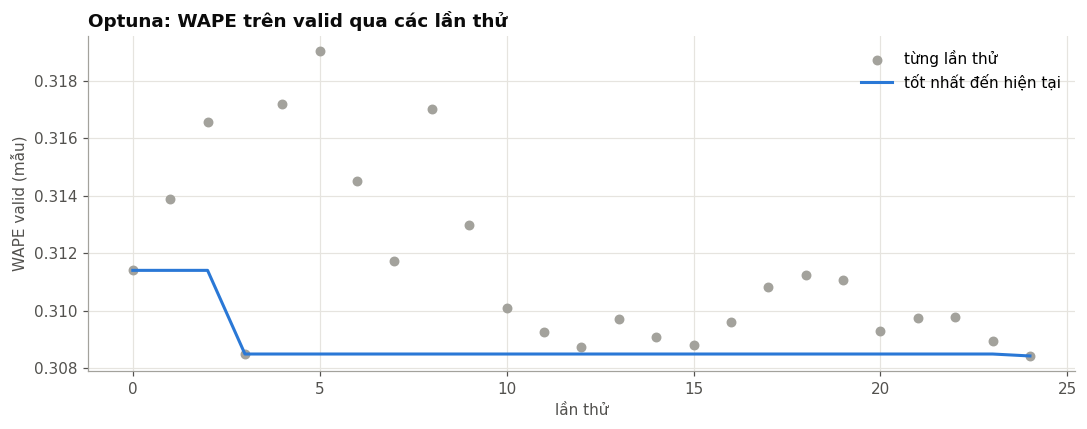

In [7]:
trials = study.trials_dataframe()
trials.to_csv(OUT_DIR / "tables" / "optuna_trials.csv", index=False)
fig, ax = plt.subplots()
ax.scatter(trials.number, trials.value, s=30, color=MUTED, label="từng lần thử", zorder=2)
ax.plot(trials.number, trials.value.cummin(), color=C1, label="tốt nhất đến hiện tại", zorder=3)
ax.set_title("Optuna: WAPE trên valid qua các lần thử"); ax.set_xlabel("lần thử"); ax.set_ylabel("WAPE valid (mẫu)")
ax.legend()
save(fig, "fc_optuna_history")

## 5. Mô hình cuối và đánh giá trên test

Huấn luyện lại trên **toàn bộ** train với tham số tốt nhất, early stopping trên valid, đánh giá một lần duy nhất trên test.

In [8]:
final_params = {**best, "bagging_freq": 1, "monotone_constraints": MONOTONE,
                "monotone_constraints_method": "advanced", "metric": "None", "verbose": -1, "seed": RANDOM_STATE}
t0 = time.time()
model = lgb.train(final_params, dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva], feval=lgb_wape,
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
print(f"best_iteration = {model.best_iteration} | {(time.time() - t0) / 60:.1f} phút")

te = te.copy()
te["pred"] = model.predict(te[FEATURES], num_iteration=model.best_iteration)
RESULTS["LightGBM (Optuna + monotone)"] = metrics(te[TARGET], te.pred)
res = pd.DataFrame(RESULTS).T
base_wape = res.loc["Moving Average 7 ngày", "WAPE"]
res["WAPE giảm so với MA7"] = 1 - res.WAPE / base_wape
res.to_csv(OUT_DIR / "tables" / "table_4_metrics.csv")
res.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "WAPE": "{:.2%}", "WAPE giảm so với MA7": "{:+.1%}"})

best_iteration = 911 | 6.2 phút


,MAE,RMSE,WAPE,WAPE giảm so với MA7
Moving Average 7 ngày,0.4668,0.7270,34.96%,+0.0%
Seasonal Naive (lag 7),0.5909,0.9201,44.26%,-26.6%
LightGBM (mặc định),0.4299,0.6929,32.20%,+7.9%
LightGBM (Optuna + monotone),0.4290,0.6932,32.13%,+8.1%


In [9]:
# Sai số theo nhóm ngành và nhóm sản phẩm bán chạy
te["ma7"] = te.rolling_mean_7
def group_table(col):
    rows = []
    for k, g in te.groupby(col, observed=True):
        mm, mb = metrics(g[TARGET], g.pred), metrics(g[TARGET], g.ma7)
        rows.append({col: k, "số dòng": len(g), "WAPE LightGBM": mm["WAPE"], "WAPE MA7": mb["WAPE"]})
    return pd.DataFrame(rows)
by_group = group_table("el_group")
by_top = group_table("top20_product").replace({"top20_product": {1: "top 20% sản phẩm", 0: "80% còn lại"}})
pd.concat([by_group.rename(columns={"el_group": "nhóm"}), by_top.rename(columns={"top20_product": "nhóm"})]) \
  .to_csv(OUT_DIR / "tables" / "table_6_1_error_by_group.csv", index=False)
display(by_group.style.format({"WAPE LightGBM": "{:.2%}", "WAPE MA7": "{:.2%}"}))
display(by_top.style.format({"WAPE LightGBM": "{:.2%}", "WAPE MA7": "{:.2%}"}))

,el_group,số dòng,WAPE LightGBM,WAPE MA7
0,Chưa kết luận,3770,42.00%,45.85%
1,Co giãn vừa,305352,32.25%,34.03%
2,Rất co giãn,123585,34.67%,41.34%
3,Ít co giãn,169643,30.23%,32.14%


,top20_product,số dòng,WAPE LightGBM,WAPE MA7
0,80% còn lại,133958,38.48%,42.92%
1,top 20% sản phẩm,468392,31.18%,33.77%


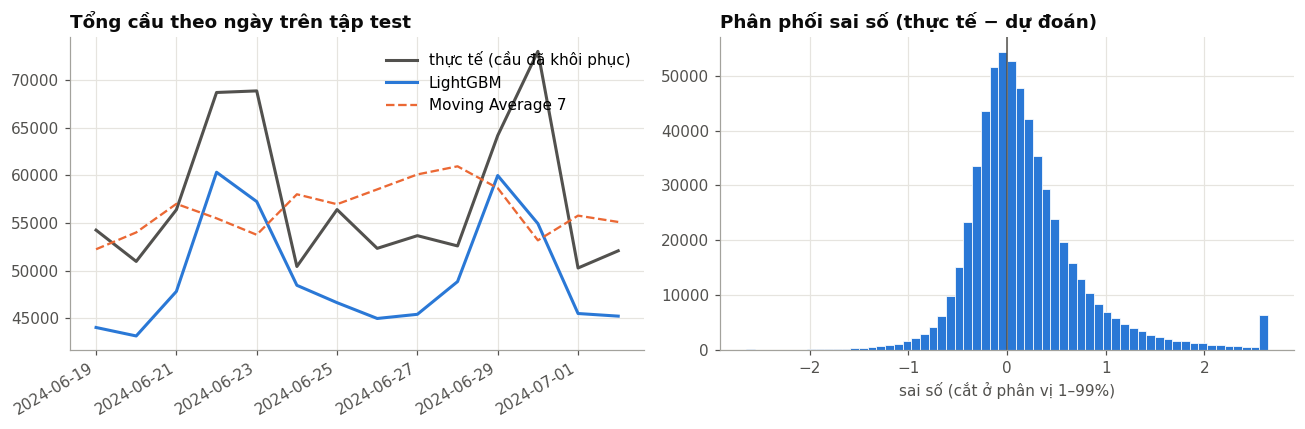

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
daily = te.groupby("dt")[[TARGET, "pred", "ma7"]].sum()
ax[0].plot(daily.index, daily[TARGET], color=INK2, label="thực tế (cầu đã khôi phục)")
ax[0].plot(daily.index, daily.pred, color=C1, label="LightGBM")
ax[0].plot(daily.index, daily.ma7, color=C2, lw=1.5, ls="--", label="Moving Average 7")
ax[0].set_title("Tổng cầu theo ngày trên tập test"); ax[0].legend()
for lbl in ax[0].get_xticklabels():
    lbl.set_rotation(30); lbl.set_ha("right")

err = (te[TARGET] - te.pred)
lim = np.quantile(np.abs(err), 0.99)
ax[1].hist(err.clip(-lim, lim), bins=60, color=C1, edgecolor="white", linewidth=0.5)
ax[1].axvline(0, color=INK2, lw=1)
ax[1].set_title("Phân phối sai số (thực tế − dự đoán)"); ax[1].set_xlabel("sai số (cắt ở phân vị 1–99%)")
save(fig, "fc_actual_vs_pred")

## 6. Feature importance

Theo **gain** (tổng mức giảm sai số mà feature đóng góp). Feature importance cho biết mô hình dựa vào biến nào, **không** chứng minh tác động nhân quả của discount; phần đó do mục 7 kiểm chứng.

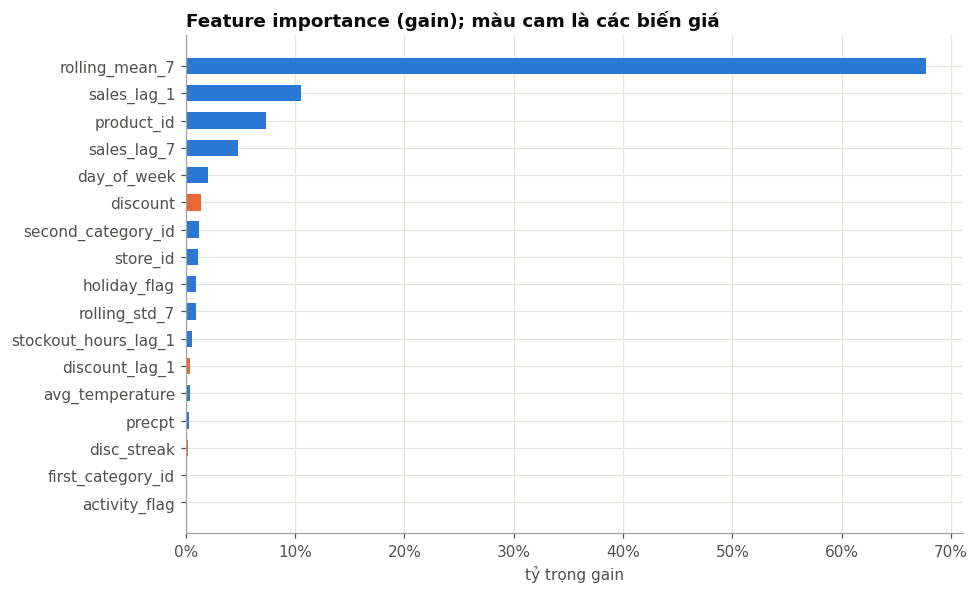

Nhóm biến giá chiếm 2.1% tổng gain


In [11]:
imp = pd.DataFrame({"feature": FEATURES, "gain": model.feature_importance("gain")})
imp["share"] = imp.gain / imp.gain.sum()
imp = imp.sort_values("share")
imp.to_csv(OUT_DIR / "tables" / "table_4_5_feature_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [C2 if f in ("discount", "discount_lag_1", "disc_streak") else C1 for f in imp.feature]
ax.barh(imp.feature, imp.share, color=colors, height=0.6)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Feature importance (gain); màu cam là các biến giá"); ax.set_xlabel("tỷ trọng gain")
save(fig, "fc_feature_importance")
print(f"Nhóm biến giá chiếm {imp[imp.feature.isin(['discount', 'discount_lag_1', 'disc_streak'])].share.sum():.1%} tổng gain")

## 7. Kiểm chứng phản ứng giá (mục 4.6)

Với một mẫu dòng test, giữ nguyên mọi bối cảnh và chỉ đổi discount (cập nhật `disc_streak` cho nhất quán), dự đoán cầu ở từng mức trong lưới giá. Độ co giãn ngầm định giữa d = 1,0 và d = 0,8:

```
ε = ln(Q̂(0,8) / Q̂(1,0)) / ln(0,8)
```

So sánh với hồi quy fixed effects ở notebook 01. Hai nguồn độc lập cho ra con số gần nhau là bằng chứng mô hình học đúng quan hệ giá–cầu, không chỉ dự báo tốt.

In [12]:
GRID = meta["discount_grid"]

def apply_discount(X, d, streak_prev):
    X = X.copy()
    X["discount"] = np.float32(d)
    X["disc_streak"] = np.where(d < 0.995, streak_prev + 1, 0).astype("int16")
    return X

samp = te.sample(min(ELAST_SAMPLE, len(te)), random_state=RANDOM_STATE)
Xs, prev = samp[FEATURES], samp.disc_streak_prev.values
Q = pd.DataFrame({d: model.predict(apply_discount(Xs, d, prev), num_iteration=model.best_iteration) for d in GRID},
                 index=samp.index).clip(lower=1e-6)

eps_row = np.log(Q[0.8] / Q[1.0]) / np.log(0.8)
w = Q[1.0]
overall_model_el = float(np.average(eps_row, weights=w))
overall_fe = float(el.elasticity.mean()) if "elasticity" in el else np.nan
summ01 = OUT_DIR / "tables" / "eda_summary.json"
fe_overall = json.load(open(summ01, encoding="utf-8"))["elasticity_overall"]["elasticity"] if summ01.exists() else overall_fe
print(f"Độ co giãn ngầm định của LightGBM (bình quân theo cầu): {overall_model_el:.2f} | fixed effects: {fe_overall:.2f}")
print(f"Tỷ lệ dòng có Q̂ không tăng khi giảm giá (vi phạm đơn điệu): {(Q[0.7] < Q[1.0] - 1e-9).mean():.2%}")

cmp = (pd.DataFrame({"cat": samp.first_category_id.astype(int).values, "eps": eps_row.values, "w": w.values})
       .groupby("cat").apply(lambda g: pd.Series({"model_el": np.average(g.eps, weights=g.w), "n": len(g)}))
       .reset_index().merge(el[["first_category_id", "elasticity", "nhom"]], left_on="cat", right_on="first_category_id"))
cmp = cmp[cmp.n >= 200]
corr = cmp[["model_el", "elasticity"]].corr().iloc[0, 1] if len(cmp) > 2 else np.nan
cmp.to_csv(OUT_DIR / "tables" / "table_4_6_elasticity_model_vs_fe.csv", index=False)
print(f"Tương quan độ co giãn theo ngành (LightGBM vs fixed effects): {corr:.2f} trên {len(cmp)} ngành")

Độ co giãn ngầm định của LightGBM (bình quân theo cầu): -0.99 | fixed effects: -2.01
Tỷ lệ dòng có Q̂ không tăng khi giảm giá (vi phạm đơn điệu): 0.00%


/tmp/ipykernel_1593/2845389329.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .groupby("cat").apply(lambda g: pd.Series({"model_el": np.average(g.eps, weights=g.w), "n": len(g)}))


Tương quan độ co giãn theo ngành (LightGBM vs fixed effects): 0.51 trên 22 ngành


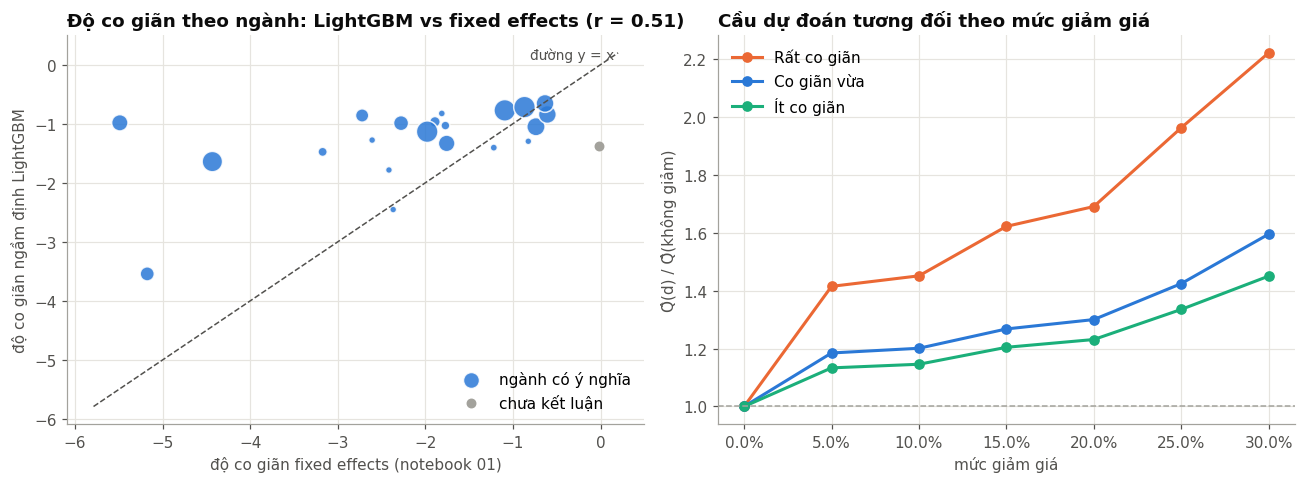

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ok = cmp.nhom != "Chưa kết luận"
ax[0].scatter(cmp.loc[ok, "elasticity"], cmp.loc[ok, "model_el"], s=np.clip(cmp.loc[ok, "n"] / 20, 20, 200),
              color=C1, alpha=0.85, edgecolor="white", label="ngành có ý nghĩa")
if (~ok).any():
    ax[0].scatter(cmp.loc[~ok, "elasticity"], cmp.loc[~ok, "model_el"], s=30, color=MUTED, label="chưa kết luận")
lo = float(min(cmp.elasticity.min(), cmp.model_el.min(), -1)) - 0.3
ax[0].plot([lo, 0.2], [lo, 0.2], color=INK2, lw=1, ls="--")
ax[0].text(0.15, 0.1, "đường y = x", color=INK2, fontsize=9, ha="right")
ax[0].set_xlabel("độ co giãn fixed effects (notebook 01)"); ax[0].set_ylabel("độ co giãn ngầm định LightGBM")
ax[0].set_title(f"Độ co giãn theo ngành: LightGBM vs fixed effects (r = {corr:.2f})"); ax[0].legend(loc="lower right")

curve = (Q.div(Q[1.0], axis=0)).groupby(samp.el_group.values).mean()
order = [g for g in ["Rất co giãn", "Co giãn vừa", "Ít co giãn"] if g in curve.index]
for g, c in zip(order, [C2, C1, C3]):
    ax[1].plot([1 - d for d in GRID], curve.loc[g, GRID].values, marker="o", color=c, label=g)
ax[1].axhline(1, color=MUTED, ls="--", lw=1)
ax[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax[1].set_title("Cầu dự đoán tương đối theo mức giảm giá"); ax[1].set_xlabel("mức giảm giá"); ax[1].set_ylabel("Q̂(d) / Q̂(không giảm)")
ax[1].legend()
save(fig, "fc_price_response")

## 8. Lưu kết quả cho notebook 04

In [14]:
model.save_model(str(OUT_DIR / "models" / "lgbm_demand.txt"), num_iteration=model.best_iteration)
json.dump({"params": final_params, "best_iteration": model.best_iteration, "optuna_best_valid_wape_sample": study.best_value,
           "features": FEATURES, "cat_features": CAT_FEATURES,
           "categories": {c: [int(x) for x in df[c].cat.categories] for c in CAT_FEATURES}},
          open(OUT_DIR / "models" / "lgbm_demand_meta.json", "w"), indent=2, default=str)
te[["series_id", "store_id", "product_id", "first_category_id", "dt", TARGET, "pred", "ma7", "discount",
    "el_group", "top20_product"]].to_parquet(OUT_DIR / "data" / "test_predictions.parquet", index=False)

lg, ma = RESULTS["LightGBM (Optuna + monotone)"], RESULTS["Moving Average 7 ngày"]
summary = pd.DataFrame([
    ("WAPE test: LightGBM vs MA7", f"{lg['WAPE']:.2%} vs {ma['WAPE']:.2%} (giảm {1 - lg['WAPE'] / ma['WAPE']:.1%})"),
    ("Hàm mục tiêu được chọn", best["objective"]),
    ("Biến giá trong tổng gain", f"{imp[imp.feature.isin(['discount', 'discount_lag_1', 'disc_streak'])].share.sum():.1%}"),
    ("Độ co giãn: LightGBM vs fixed effects", f"{overall_model_el:.2f} vs {fe_overall:.2f}"),
    ("Tương quan độ co giãn theo ngành", f"r = {corr:.2f} ({len(cmp)} ngành)"),
    ("Vi phạm đơn điệu", f"{(Q[0.7] < Q[1.0] - 1e-9).mean():.2%}"),
], columns=["Chỉ tiêu", "Kết quả"])
summary.to_csv(OUT_DIR / "tables" / "fc_summary.csv", index=False)
summary

,Chỉ tiêu,Kết quả
0,WAPE test: LightGBM vs MA7,32.13% vs 34.96% (giảm 8.1%)
1,Hàm mục tiêu được chọn,tweedie
2,Biến giá trong tổng gain,2.1%
3,Độ co giãn: LightGBM vs fixed effects,-0.99 vs -2.01
4,Tương quan độ co giãn theo ngành,r = 0.51 (22 ngành)
5,Vi phạm đơn điệu,0.00%
